<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Meeting durations double-count overlapping time

**How much time do a selected set of calendar events actually occupy?**
We will parse an iCalendar file, declare which events belong in a timed schedule,
add an optional buffer, and merge overlapping intervals in SQL. A timeline will show
the individual reservations beside their union; another chart will compare summed
duration with occupied time.

The [calendar file](assets/synthetic-day.ics) is entirely synthetic: nine event
components and three to-dos, with no personal calendar or external API. The result
describes an explicit subset of that file, not complete availability for a person.

## Choose a buffer around each selected event

`BUFFER_MINUTES=0` uses the original event intervals. The experiment sets it to `15`,
reserving fifteen minutes before and after each selected event. The observation
window stays fixed at **08:00–17:00 UTC on 5 January 2026**; intervals are clipped to
that window. We use half-open intervals: an end touching another start is not an overlap.
[Run instructions](README.md).

In [1]:
BUFFER_MINUTES = 0

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch
from IPython.display import display
from notebook_support import finish, prose, theme

if type(BUFFER_MINUTES) is not int or not 0 <= BUFFER_MINUTES <= 60:
    raise ValueError("BUFFER_MINUTES must be an integer from 0 to 60.")
schedule = blocks = metrics = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ical/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ical/notebooks/pyproject.toml.

## Connect to the released parser

The literal location downloads the public v0.4.1 JAR, checks its SHA-256 and starts
Java 21+. No Gradle or local worker build is needed. A VARCHAR argument to this
worker is a **file path**; inline calendar text must be encoded as BLOB bytes.
We use a relative path inside the complete portable notebook directory.

The worker emits timestamps with time zones. SQL explicitly converts them to UTC
for this analysis, so the kernel's display time zone cannot change the schedule.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
LOAD icu;
ATTACH 'ical' (TYPE vgi,
 LOCATION 'uv run --frozen --project . python release_jar.py Query-farm/vgi-ical v0.4.1 vgi-ical-v0.4.1.jar f575983fd1ac579adc6b150bbaafc86606933db8968be8b868168a80670378cf');
CREATE TABLE analysis_window AS
 SELECT TIMESTAMP '2026-01-05 08:00:00' AS window_start,
        TIMESTAMP '2026-01-05 17:00:00' AS window_end;

,Count


## Distinguish a valid empty feed from an unreadable one

The scalar functions accept a column of BLOBs from `read_blob`. Both the empty
calendar and the deliberately unparseable fixture have zero event rows, but their
parse flags differ. Event count alone cannot tell them apart. A successful parse
also does not guarantee that every component in an arbitrary feed was preserved:
the worker uses relaxed parsing and can skip unreadable components.

In [4]:
%%sql
CREATE TABLE feed_audit AS
 SELECT parse_filename(filename) AS file,
        ical.main.is_valid_ical(content) AS parses,
        ical.main.ical_calendar_name(content) AS calendar_name,
        ical.main.ical_event_count(content) AS event_count
 FROM read_blob('assets/*.ics');
CREATE TABLE events AS SELECT * FROM ical.main.ical_events('assets/synthetic-day.ics');
CREATE TABLE todos AS SELECT * FROM ical.main.ical_todos('assets/synthetic-day.ics');
SELECT * FROM feed_audit ORDER BY file;

,file,parses,calendar_name,event_count
0,empty.ics,True,-//Query Farm//Synthetic empty fixture//EN,0
1,synthetic-day.ics,True,Synthetic Operations Day,9
2,unparseable.ics,False,None,0


## Declare the timed-schedule policy before aggregating

We include only confirmed, non-recurring, timed events with an explicit usable start
and end in the worker output. Cancelled and tentative events stay in the inventory.
All-day dates are kept separate from timed meetings. RRULE is returned as text; this
worker emits one row per VEVENT and does not expand recurring occurrences.

The duration-only reminder has `DURATION:PT30M` in the source, but this release does
not project that property or derive `dtend` from it. We retain its unknown end in
this analysis instead of inventing a zero-length interval. All timed sample inputs
use explicit UTC (`Z`); floating and zoned-time policies are outside this example.

In [5]:
%%sql
CREATE TABLE classified AS
 SELECT uid,summary,timezone('UTC',dtstart) AS start_utc,timezone('UTC',dtend) AS end_utc,
        all_day,status,rrule,
 CASE WHEN all_day THEN 'All-day date'
      WHEN rrule IS NOT NULL THEN 'Recurrence not expanded'
      WHEN status='CANCELLED' THEN 'Cancelled'
      WHEN status IS DISTINCT FROM 'CONFIRMED' THEN 'Not confirmed'
      WHEN dtstart IS NULL OR dtend IS NULL THEN 'Missing projected bound'
      WHEN dtend<=dtstart THEN 'Nonpositive interval'
      ELSE 'Eligible timed event' END AS scope
 FROM events;
SELECT summary,start_utc,end_utc,status,rrule,scope FROM classified ORDER BY start_utc,uid;

,summary,start_utc,end_utc,status,rrule,scope
0,All-day milestone,2026-01-05 00:00:00,2026-01-06 00:00:00,CONFIRMED,None,All-day date
1,Recurring reminder,2026-01-05 08:00:00,2026-01-05 08:30:00,CONFIRMED,FREQ=DAILY;COUNT=3,Recurrence not expanded
2,Morning brief,2026-01-05 09:00:00,2026-01-05 10:00:00,CONFIRMED,None,Eligible timed event
3,Design review,2026-01-05 09:30:00,2026-01-05 10:30:00,CONFIRMED,None,Eligible timed event
4,Cancelled review,2026-01-05 10:30:00,2026-01-05 11:00:00,CANCELLED,None,Cancelled
5,Focus session,2026-01-05 11:00:00,2026-01-05 12:00:00,CONFIRMED,None,Eligible timed event
6,Handoff,2026-01-05 12:00:00,2026-01-05 12:30:00,CONFIRMED,None,Eligible timed event
7,Duration-only reminder,2026-01-05 14:00:00,NaT,CONFIRMED,None,Missing projected bound
8,Tentative discussion,2026-01-05 15:00:00,2026-01-05 16:00:00,TENTATIVE,None,Not confirmed


## Reserve intervals and inspect real overlaps

Apply the selected buffer, clip to the fixed window, and retain only positive
intervals. The self-join lists each overlapping pair once using the unique sample
UIDs. Its strict inequalities keep touching endpoints out of the conflict list.
The source event times remain unchanged beside the reservation times.

In [6]:
%%sql
CREATE TABLE reservations AS
 SELECT c.*,greatest(start_utc-INTERVAL '{{ BUFFER_MINUTES }} MINUTE',w.window_start) AS reserved_start,
            least(end_utc+INTERVAL '{{ BUFFER_MINUTES }} MINUTE',w.window_end) AS reserved_end
 FROM classified c CROSS JOIN analysis_window w WHERE scope='Eligible timed event';
DELETE FROM reservations WHERE reserved_end<=reserved_start;
CREATE TABLE event_overlaps AS
 SELECT a.uid AS first_uid,b.uid AS second_uid,a.summary AS first_event,b.summary AS second_event,
        greatest(a.reserved_start,b.reserved_start) AS overlap_start,
        least(a.reserved_end,b.reserved_end) AS overlap_end
 FROM reservations a JOIN reservations b ON a.uid<b.uid
 AND a.reserved_start<b.reserved_end AND b.reserved_start<a.reserved_end;
SELECT first_event,second_event,overlap_start,overlap_end,
 date_diff('minute',overlap_start,overlap_end) AS overlap_minutes
FROM event_overlaps ORDER BY overlap_start,first_event;

,first_event,second_event,overlap_start,overlap_end,overlap_minutes
0,Morning brief,Design review,2026-01-05 09:30:00,2026-01-05 10:00:00,30


## Merge the interval union in SQL

Compare each start with the latest end of **all preceding intervals**. Looking only
at the immediately previous interval can fail when one interval contains another.
A new block starts only after that running end. Touching intervals can share a
contiguous occupied block without becoming a conflicting pair.

In [7]:
%%sql
CREATE TABLE ordered_reservations AS
 SELECT *,max(reserved_end) OVER(ORDER BY reserved_start,reserved_end,uid
   ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS prior_latest_end
 FROM reservations;
CREATE TABLE numbered_reservations AS
 SELECT *,sum(CASE WHEN prior_latest_end IS NULL OR reserved_start>prior_latest_end THEN 1 ELSE 0 END)
 OVER(ORDER BY reserved_start,reserved_end,uid ROWS UNBOUNDED PRECEDING) AS block_id
 FROM ordered_reservations;
CREATE TABLE occupied_blocks AS
 SELECT block_id,min(reserved_start) AS block_start,max(reserved_end) AS block_end
 FROM numbered_reservations GROUP BY block_id;
SELECT *,date_diff('minute',block_start,block_end) AS occupied_minutes
FROM occupied_blocks ORDER BY block_start;

,block_id,block_start,block_end,occupied_minutes
0,1.0,2026-01-05 09:00:00,2026-01-05 10:30:00,90
1,2.0,2026-01-05 11:00:00,2026-01-05 12:30:00,90


In [8]:
%%sql schedule <<
SELECT * FROM reservations ORDER BY start_utc,uid;

In [9]:
%%sql blocks <<
SELECT * FROM occupied_blocks ORDER BY block_start;

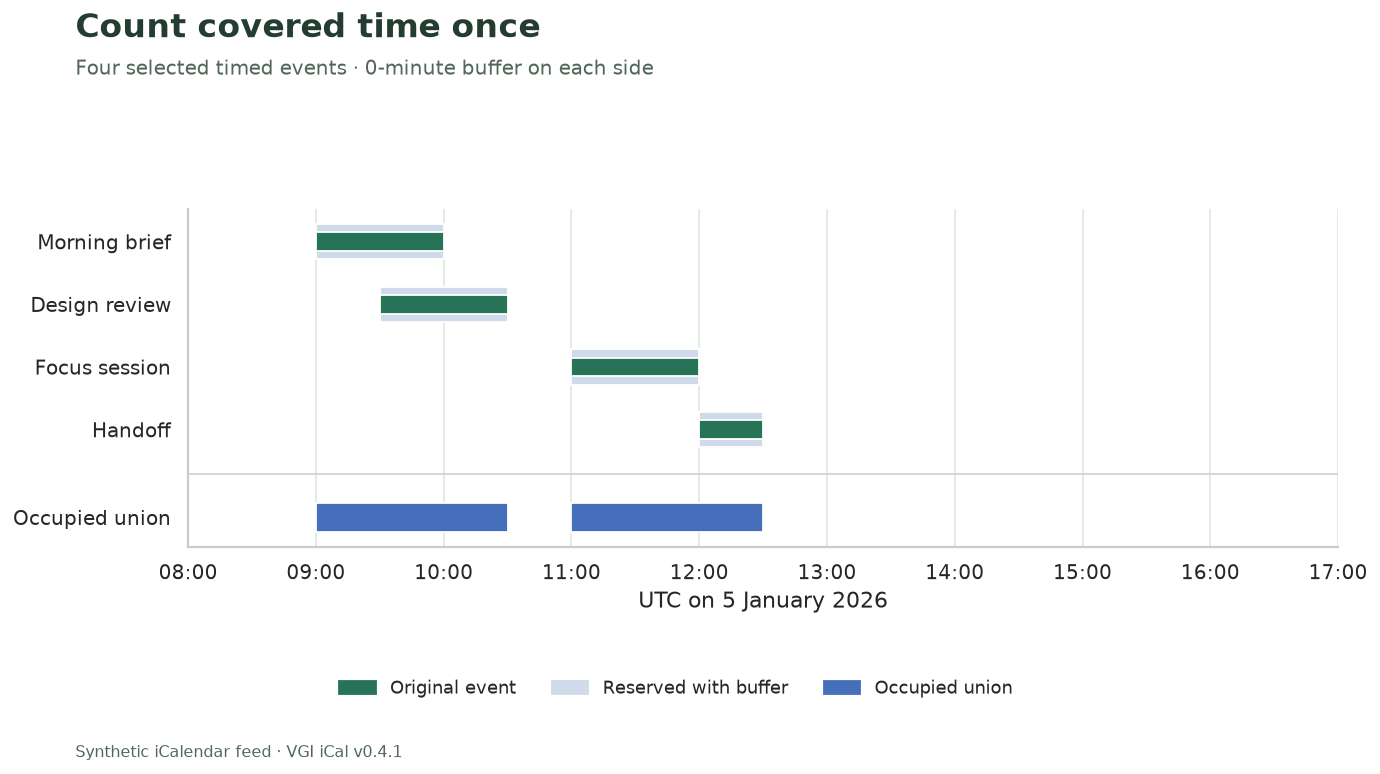

The **4 selected events** form **2 occupied block(s)** after buffering. Their original times are unchanged. The union describes only the selected subset; the excluded recurring, all-day, unconfirmed and incomplete projections prevent a claim about complete availability.

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))
for y, row in enumerate(schedule.itertuples()):
    for start, end, color, height in [
        (row.reserved_start, row.reserved_end, "#cfdbeb", 0.56),
        (row.start_utc, row.end_utc, "#267358", 0.30),
    ]:
        ax.barh(
            y,
            mdates.date2num(end) - mdates.date2num(start),
            left=mdates.date2num(start),
            height=height,
            color=color,
        )
union_y = len(schedule) + 0.4
for row in blocks.itertuples():
    ax.barh(
        union_y,
        mdates.date2num(row.block_end) - mdates.date2num(row.block_start),
        left=mdates.date2num(row.block_start),
        height=0.45,
        color="#456fba",
    )
ax.axhline(len(schedule) - 0.3, color="#cbd5cf", lw=1)
ax.set_yticks(
    list(range(len(schedule))) + [union_y], schedule.summary.tolist() + ["Occupied union"]
)
ax.invert_yaxis()
ax.set_xlim(
    mdates.date2num(pd.Timestamp("2026-01-05 08:00")),
    mdates.date2num(pd.Timestamp("2026-01-05 17:00")),
)
ax.xaxis.set_major_locator(mdates.HourLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel("UTC on 5 January 2026")
ax.grid(axis="y", visible=False)
fig.legend(
    handles=[
        Patch(color="#267358", label="Original event"),
        Patch(color="#cfdbeb", label="Reserved with buffer"),
        Patch(color="#456fba", label="Occupied union"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 0.08),
    ncol=3,
    frameon=False,
    fontsize=10,
)
finish(
    fig,
    "Count covered time once",
    f"Four selected timed events · {BUFFER_MINUTES}-minute buffer on each side",
    "01_occupied_timeline.png",
    bottom=0.18,
)
prose(
    f"The **{len(schedule)} selected events** form **{len(blocks)} occupied block(s)** after buffering. "
    "Their original times are unchanged. The union describes only the selected subset; "
    "the excluded recurring, all-day, unconfirmed and incomplete projections prevent a claim about complete availability."
)

## Separate summed duration from occupied time

The sum counts every selected reservation independently. The union counts each
covered minute once. Their difference is duplicate counting in the sum; with three
simultaneous reservations, one minute contributes two extra minutes to that difference.
It is not generally the same as a count of distinct minutes with any conflict.

In [11]:
%%sql metrics <<
SELECT (SELECT count(*) FROM reservations) AS selected_events,
       (SELECT sum(date_diff('minute',reserved_start,reserved_end)) FROM reservations) AS summed_minutes,
       (SELECT sum(date_diff('minute',block_start,block_end)) FROM occupied_blocks) AS occupied_minutes,
       (SELECT count(*) FROM event_overlaps) AS overlapping_pairs,
       (SELECT date_diff('minute',window_start,window_end) FROM analysis_window) AS window_minutes;

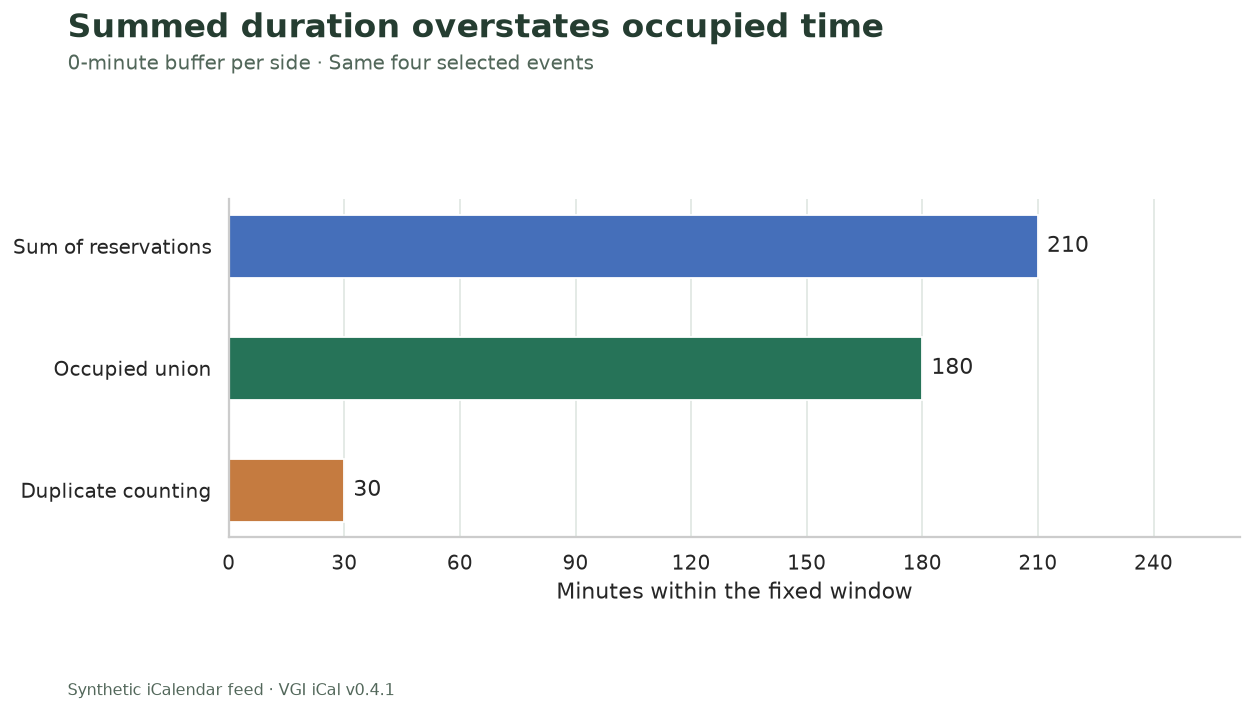

Reservations sum to **210 minutes**, but their union occupies **180 minutes** of the 540-minute window. The sum includes **30 minutes of duplicate counting**. The strict overlap query finds **1 event pair(s)**.

In [12]:
r = metrics.iloc[0]
duplicate = int(r.summed_minutes - r.occupied_minutes)
values = [int(r.summed_minutes), int(r.occupied_minutes), duplicate]
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(
    ["Sum of reservations", "Occupied union", "Duplicate counting"],
    values,
    color=["#456fba", "#267358", "#c57b40"],
    height=0.52,
)
ax.bar_label(bars, padding=5, fontsize=12)
ax.invert_yaxis()
ax.set_xlim(0, max(values) * 1.25)
ax.set_xlabel("Minutes within the fixed window")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Summed duration overstates occupied time",
    f"{BUFFER_MINUTES}-minute buffer per side · Same four selected events",
    "02_duration_and_union.png",
    bottom=0.12,
)
prose(
    f"Reservations sum to **{int(r.summed_minutes)} minutes**, but their union occupies "
    f"**{int(r.occupied_minutes)} minutes** of the {int(r.window_minutes)}-minute window. "
    f"The sum includes **{duplicate} minutes of duplicate counting**. "
    f"The strict overlap query finds **{int(r.overlapping_pairs)} event pair(s)**."
)

## Inspect to-dos without assigning them meeting durations

`ical_todos` returns separate VTODO rows. A due time is not a time reservation and
does not imply a link to any event. This fixed-window audit distinguishes a completed
item, an open item due before the window starts, and an item whose due time is absent.
It makes no assertion about whether work was actually completed beyond the stored status.

In [13]:
%%sql
SELECT uid,summary,timezone('UTC',due) AS due_utc,status,
 CASE WHEN status='COMPLETED' THEN 'Marked completed'
      WHEN due IS NULL THEN 'Due time absent'
      WHEN timezone('UTC',due)<window_start THEN 'Open: due before window'
      ELSE 'Open: due at or after window start' END AS due_state
FROM todos CROSS JOIN analysis_window ORDER BY uid;

,uid,summary,due_utc,status,due_state
0,todo-done@example.invalid,Print schedule,2026-01-05 07:00:00,COMPLETED,Marked completed
1,todo-open@example.invalid,Prepare briefing,2026-01-05 07:30:00,NEEDS-ACTION,Open: due before window
2,todo-undated@example.invalid,Review follow-up,NaT,NEEDS-ACTION,Due time absent


## Check the population and independently verify covered minutes

The minute-grid check is valid for this sample because every boundary falls on an
exact minute. It independently counts covered one-minute slots and compares them
with the interval union. Other checks retain the rejected scope categories, original
component count, and half-open overlap rule.

In [14]:
%%sql checks <<
SELECT 'Parsed event rows reconcile with the scalar inventory' AS invariant,
 (SELECT count(*) FROM events)=(SELECT event_count FROM feed_audit WHERE file='synthetic-day.ics') AS passed
UNION ALL SELECT 'All nine synthetic event UIDs are unique and retained',
 (SELECT count(*)=9 AND count(DISTINCT uid)=9 FROM classified)
UNION ALL SELECT 'Every event has one scope category and four are eligible',
 (SELECT count(*) FILTER(WHERE scope IS NOT NULL)=9 AND count(*) FILTER(WHERE scope='Eligible timed event')=4 FROM classified)
UNION ALL SELECT 'Recurring component remains one unexpanded row',
 (SELECT count(*)=1 AND min(rrule)='FREQ=DAILY;COUNT=3' FROM events WHERE rrule IS NOT NULL)
UNION ALL SELECT 'Duration-only event retains a missing projected end',
 (SELECT end_utc IS NULL AND scope='Missing projected bound' FROM classified WHERE uid='duration@example.invalid')
UNION ALL SELECT 'Reservations are positive and bounded by the analysis window',
 NOT EXISTS(SELECT 1 FROM reservations CROSS JOIN analysis_window
   WHERE reserved_start<window_start OR reserved_end>window_end OR reserved_end<=reserved_start)
UNION ALL SELECT 'No excluded event enters the reservation table',
 NOT EXISTS(SELECT 1 FROM reservations WHERE scope!='Eligible timed event')
UNION ALL SELECT 'Merged blocks are strictly separated',
 NOT EXISTS(SELECT 1 FROM occupied_blocks a JOIN occupied_blocks b ON a.block_id<b.block_id AND a.block_end>=b.block_start)
UNION ALL SELECT 'Minute-grid coverage equals the interval union',
 (SELECT count(*) FROM analysis_window w,LATERAL generate_series(w.window_start,w.window_end-INTERVAL 1 MINUTE,INTERVAL 1 MINUTE) t(minute)
  WHERE EXISTS(SELECT 1 FROM reservations r WHERE t.minute>=r.reserved_start AND t.minute<r.reserved_end))
 =(SELECT sum(date_diff('minute',block_start,block_end)) FROM occupied_blocks)
UNION ALL SELECT 'Every reported overlap has positive duration',
 NOT EXISTS(SELECT 1 FROM event_overlaps WHERE overlap_end<=overlap_start)
UNION ALL SELECT 'Empty and unparseable calendars both have zero events but different parse flags',
 (SELECT parses AND event_count=0 FROM feed_audit WHERE file='empty.ics')
 AND (SELECT NOT parses AND event_count=0 FROM feed_audit WHERE file='unparseable.ics')
UNION ALL SELECT 'Three todos stay separate, including one without a due time',
 (SELECT count(*)=3 AND count(*) FILTER(WHERE due IS NULL)=1 FROM todos);

In [15]:
display(checks)
assert checks.passed.eq(True).all(), checks.loc[~checks.passed].to_dict("records")
prose(
    f"**{len(checks)} checks passed.** The occupied-minute calculation reconciles independently "
    "within the declared subset and window; it does not resolve the excluded event semantics."
)

,invariant,passed
0,Parsed event rows reconcile with the scalar in...,True
1,All nine synthetic event UIDs are unique and r...,True
2,Every event has one scope category and four ar...,True
3,Recurring component remains one unexpanded row,True
4,Duration-only event retains a missing projecte...,True
5,Reservations are positive and bounded by the a...,True
6,No excluded event enters the reservation table,True
7,Merged blocks are strictly separated,True
8,Minute-grid coverage equals the interval union,True
9,Every reported overlap has positive duration,True


**12 checks passed.** The occupied-minute calculation reconciles independently within the declared subset and window; it does not resolve the excluded event semantics.

## Experiment: reserve fifteen minutes on each side

Change only `BUFFER_MINUTES` to `15`, restart and run all. Predict whether the two
occupied blocks join, which previously touching events become a conflicting pair,
and whether summed duration and union duration grow by the same amount.

The input file, event selection and UTC window stay fixed. Inspect the classified
inventory as well as the charts: a buffer does not expand recurrence, interpret an
all-day event, or recover an unprojected duration. Reset to `0` for the saved default.

In [16]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)